# Savitsky Sensitivity Analysis

The default boat is [v4 with verified geometry and supplied loading](boats/v4-2026-10-30/README.md). Its reverse chines and varying sections require an equivalent-V estimate; no uniform aft region has been established. [Baseline comparison curves and results](../outputs/savitsky/v4-2026-10-30/RESULTS.md).

Displayed lengths and length controls use **inches**, areas use **square inches**. Forces remain N, power kW, mass kg and speed mph. The model and reloadable JSON use SI internally.


In [106]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'hull/savitsky_sensitivity.py').exists())
if str(ROOT / 'hull') not in sys.path:
    sys.path.insert(0, str(ROOT / 'hull'))
from savitsky_sensitivity import load_baseline, study, export_study

import display_units as units


## 1. Pick Baselines

`BASELINE_FILE` accepts the current input JSON. 

`BASELINE_OVERRIDES` changes the boat being studied. **Edit the lists at the top of the next cell** to choose your comparisons

`REQUIRE_UNIFORM_AFT = False` allows sensitivity estimates beyond the uniform aft section, with geometry flags retained. Set it to `True` to require both baseline and variant to fit that assumption.

Length overrides and scenario inputs can use inch names such as `beam_in`, `length_in`, `lcg_in`, `vcg_in`, `thrust_height_in` and `thrust_x_in`. Tables, legends and CSV exports use inches; area uses square inches. Calculations and reloadable study JSON remain SI internally. Existing SI names are still accepted for compatibility.


In [107]:
# Baseline boat: change this path to load another saved input file.
BASELINE_FILE = ROOT / 'hull/boats/v4-2026-10-30/savitsky-inputs.json'
BASELINE_OVERRIDES = {}  # e.g. {'mass_kg': 60.0, 'lcg_in': 24.0}; length overrides in inches

# EDIT THESE LISTS: each number creates a separate change from the baseline.
# Percent changes: -10 means 10% smaller/lighter; +10 means 10% larger/heavier.
# Example: add +20 to BEAM_CHANGES_PCT to also compare a 20% wider boat.
# Use [] to skip a parameter. The unchanged baseline is always included.
BEAM_CHANGES_PCT = [-20, -10, -5, +5, +10, +20]
MASS_CHANGES_PCT = [-10, -5, +5, +10, +15, +20]
LENGTH_CHANGES_PCT = [-20,-10,+20]             # e.g. [-5, +5]; changes hull-length checks, not resistance directly.

# Fixed offsets: inches for CG and thrust positions, degrees for angles.
LCG_OFFSETS_IN = [-12,-6,-1, +1,+6,+10]            # Negative = aft; positive = forward.
VCG_OFFSETS_IN = [-5,+5]                 # e.g. [-1, +1]; negative = lower; positive = higher.
THRUST_HEIGHT_OFFSETS_IN = []       # e.g. [-1, +1]; negative = lower; positive = higher.
THRUST_X_OFFSETS_IN = []            # e.g. [-1, +1]; negative = aft; positive = forward.
DEADRISE_OFFSETS_DEG = [-2, +2]      # Negative = flatter; positive = deeper V.
THRUST_ANGLE_OFFSETS_DEG = [-10,-7,-5,-2, +2]  # Added to the baseline thrust angle.

# Refresh the helper even when this notebook kernel was already running during an update.
# This preserves the adjustment lists above and avoids stale imported functions.
import importlib
import savitsky_sensitivity as _sensitivity
_sensitivity = importlib.reload(_sensitivity)
import display_units as units
units = importlib.reload(units)
load_baseline = _sensitivity.load_baseline
study = _sensitivity.study
export_study = _sensitivity.export_study

# Load the baseline and convert the lists to the absolute values the model uses.
config, imported_speeds = load_baseline(BASELINE_FILE)
config['inputs'].update(units.overrides_to_si(BASELINE_OVERRIDES))
p = config['inputs']
SPEEDS_MPH = imported_speeds or list(range(31))
VARIATIONS = {
    'length_m': [p['length_m'] * (1 + pct / 100) for pct in LENGTH_CHANGES_PCT],
    'beam_m': [p['beam_m'] * (1 + pct / 100) for pct in BEAM_CHANGES_PCT],
    'mass_kg': [p['mass_kg'] * (1 + pct / 100) for pct in MASS_CHANGES_PCT],
    'lcg_m': [p['lcg_m'] + inches * 0.0254 for inches in LCG_OFFSETS_IN],
    'vcg_m': [p['vcg_m'] + inches * 0.0254 for inches in VCG_OFFSETS_IN],
    'thrust_height_m': [p['thrust_height_m'] + inches * 0.0254 for inches in THRUST_HEIGHT_OFFSETS_IN],
    'thrust_x_m': [p['thrust_x_m'] + inches * 0.0254 for inches in THRUST_X_OFFSETS_IN],
    'deadrise_deg': [p['deadrise_deg'] + deg for deg in DEADRISE_OFFSETS_DEG],
    'thrust_angle_deg': [p['thrust_angle_deg'] + deg for deg in THRUST_ANGLE_OFFSETS_DEG],
}
SCENARIOS = {}  # e.g. {'battery move': {'lcg_in': 24.4, 'vcg_in': 5.5}}
REQUIRE_UNIFORM_AFT = False


payload = study(config, SPEEDS_MPH, VARIATIONS,
                {name: units.overrides_to_si(changes) for name, changes in SCENARIOS.items()},
                REQUIRE_UNIFORM_AFT)
curves = pd.DataFrame(payload['results'])
sensitivity = pd.DataFrame(payload['sensitivities'])
print('Equation fingerprint:', payload['engine_functions_sha256'])
print('Display units: lengths in; areas in²; mass kg; angles deg; speed mph; force N; effective power kW.')
display(pd.DataFrame([{'input': units.column_info(k)[0],
                      'baseline': units.value_in_inches(k, v),
                      'unit': units.column_info(k)[2]}
                     for k, v in p.items()]))
display(curves.groupby('scenario', sort=False).agg(
    points=('speed_mph', 'size'), solved=('solved', 'sum'),
    within_screen=('screen_ok', 'sum'), within_uniform_aft=('geometry_ok', 'sum')).rename(index=units.scenario_label))
print('Sensitivity outside uniform aft section:', not REQUIRE_UNIFORM_AFT)


Equation fingerprint: beea4b9359303787728b3c9ba4a1cdbd7ed55d93c2c105ee1c87d572b792f567
Display units: lengths in; areas in²; mass kg; angles deg; speed mph; force N; effective power kW.


,input,baseline,unit
0,length_in,72.000000,in
1,beam_in,14.000000,in
2,mass_kg,56.747581,kg
3,deadrise_deg,20.000000,deg
4,lcg_in,23.734254,in
5,vcg_in,6.023536,in
6,thrust_height_in,-1.292286,in
7,thrust_x_in,-4.823887,in
8,thrust_angle_deg,15.000000,deg
9,density_kg_in3,0.016358,kg/in³


,points,solved,within_screen,within_uniform_aft
scenario,,,,
Baseline,31,26,24,0
length_in = 57.6 in,31,26,24,0
length_in = 64.8 in,31,26,24,0
length_in = 86.4 in,31,26,24,0
beam_in = 11.2 in,31,27,21,0
beam_in = 12.6 in,31,27,23,0
beam_in = 13.3 in,31,26,24,0
beam_in = 14.7 in,31,26,25,0
beam_in = 15.4 in,31,26,26,0


Sensitivity outside uniform aft section: True


Select `PLOT_PARAMETER`. Options:
- 'beam_in'
- 'mass_kg'
- 'length_in'
- 'lcg_in'
- 'vcg_in'
- 'deadrise_deg' 
- 'thrust_height_in'
- 'thrust_x_in'
These selectors are display names. The notebook maps them to SI fields internally.


In [108]:
PLOT_PARAMETER = 'mass_kg'
DETAIL_MPH = 10
SHOW_OUTSIDE_LIMITS = True

## 2. Speed curves

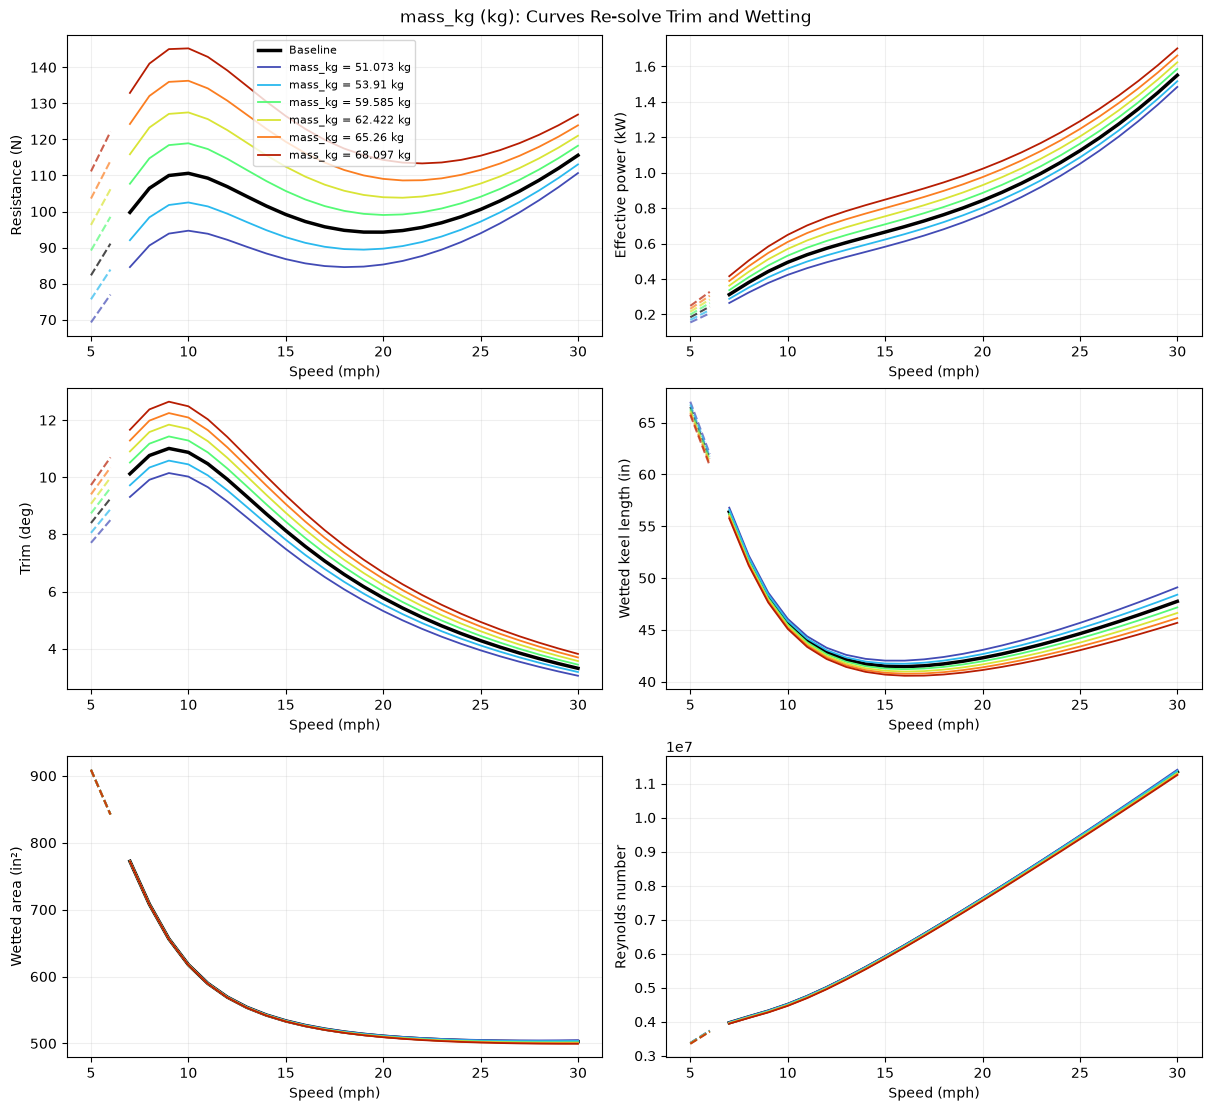

In [109]:
def label_for(name, frame):
    if name == 'baseline':
        return 'Baseline'
    row = frame.iloc[0]
    key = row['parameter']
    if pd.notna(key):
        display_key, _, unit = units.column_info(key)
        return f"{display_key} = {units.value_in_inches(key, row['parameter_value']):.5g} {unit}"
    return units.scenario_label(name)

selected = curves[(curves['scenario'] == 'baseline') |
                  (curves['parameter'] == units.si_key(PLOT_PARAMETER)) |
                  curves['scenario'].str.startswith('scenario:')]
metrics = [('resistance_n', 'Resistance (N)'), ('effective_power_kw', 'Effective power (kW)'),
           ('trim_deg', 'Trim (deg)'), ('keel_wetted_m', 'Wetted keel length (in)'),
           ('wetted_area_m2', 'Wetted area (in²)'), ('reynolds_number', 'Reynolds number')]
# Assign each variant a distinct position along a multicolor gradient.
# Reuse these colors in every chart; the baseline stays black.
names = [name for name in selected['scenario'].unique() if name != 'baseline']
cmap = plt.get_cmap('turbo').resampled(max(256, 2 * len(names)))
line_colors = {'baseline': 'black'}
for i, name in enumerate(names):
    line_colors[name] = cmap(0.08 + 0.84 * i / max(1, len(names) - 1))

fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)
for name, frame in selected.groupby('scenario', sort=False):
    frame = frame.sort_values('speed_mph')
    color = line_colors[name]
    for ax, (metric, ylabel) in zip(axes.flat, metrics):
        # Static power is deliberately not connected to the running model.
        y = frame.reindex(columns=[metric])[metric] * units.column_info(metric)[1]
        line, = ax.plot(frame['speed_mph'], y.where(frame['screen_ok']),
                        label=label_for(name, frame), color=color, linewidth=2.5 if name == 'baseline' else 1.3)
        if SHOW_OUTSIDE_LIMITS:
            ax.plot(frame['speed_mph'], y.where(frame['solved'] & ~frame['screen_ok']),
                    '--', color=line.get_color(), alpha=0.7)
        ax.set(xlabel='Speed (mph)', ylabel=ylabel)
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'{units.quantity_label(PLOT_PARAMETER)}: Curves Re-solve Trim and Wetting')
plt.show()


## 3. Pressure v. Friction

This separates the two resistance contributions. A design can reduce pressure drag while increasing friction, so neither trim nor wetted area alone is the efficiency objective.

**Pressure Drag**: backward component of the pressure force supporting the boat. Dependecies:
- Lift 
- Trim

**Friction Drag**: resistance from water flowing along the wetted bottom. Dependencies:
- Wetted area
- Speed
- Friction Coefficient


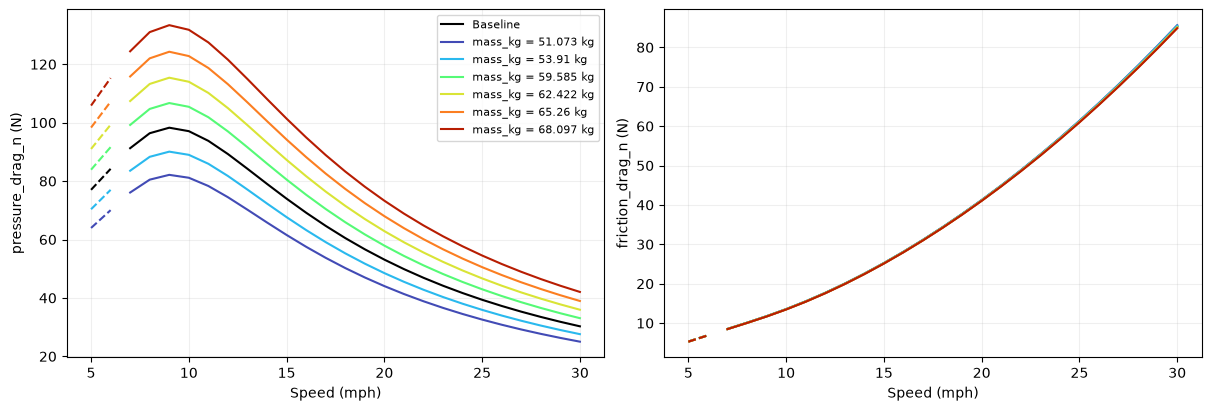

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, frame in selected.groupby('scenario', sort=False):
    frame = frame.sort_values('speed_mph')
    for ax, metric in zip(axes, ['pressure_drag_n', 'friction_drag_n']):
        y = frame.reindex(columns=[metric])[metric]
        line, = ax.plot(frame['speed_mph'], y.where(frame['screen_ok']),
                        label=label_for(name, frame), color=line_colors[name])
        if SHOW_OUTSIDE_LIMITS:
            ax.plot(frame['speed_mph'], y.where(frame['solved'] & ~frame['screen_ok']),
                    '--', color=line.get_color())
        ax.set(xlabel='Speed (mph)', ylabel=units.quantity_label(metric))
        ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
plt.show()


## 4. Sensitivity Changes over Speed Variable

**Percent change:** % difference from origninal

**Normalized sensitivity:** Compares the size change of the result to the size of our adjustment.


### **Plot Metrics**
- 'resistance_n'
- 'effective_power_kw'
- 'trim_deg'
- 'keel_wetted_in'
- 'wetted_area_in2'
- 'reynolds_number'
- 'pressure_drag_n'
- 'friction_drag_n'
- 'thrust_n'
- 'chine_wetted_in'

In [117]:
PLOT_METRIC = 'keel_wetted_in'

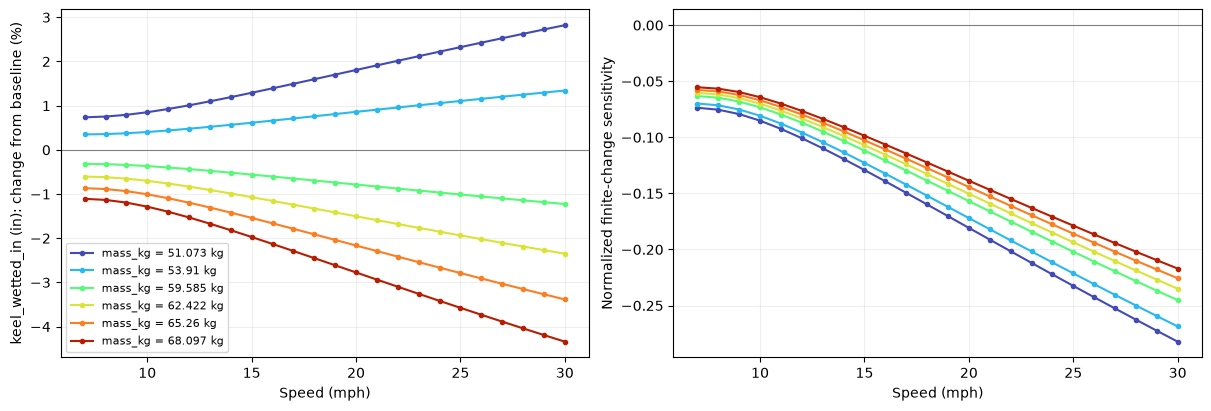

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
if not sensitivity.empty:
    subset = sensitivity[(sensitivity['parameter'] == units.si_key(PLOT_PARAMETER)) &
                         (sensitivity['metric'] == units.si_key(PLOT_METRIC))]
    for name, frame in subset.groupby('scenario', sort=False):
        frame = frame.sort_values('speed_mph')
        for ax, field in zip(axes, ['percent_change', 'elasticity']):
            ax.plot(frame['speed_mph'], frame[field], marker='.', label=label_for(name, curves[curves['scenario'] == name]), color=line_colors[name])
    for ax in axes:
        ax.axhline(0, color='gray', linewidth=0.8)
        ax.set_xlabel('Speed (mph)')
        ax.grid(alpha=0.2)
    axes[0].set_ylabel(f'{units.quantity_label(PLOT_METRIC)}: change from baseline (%)')
    axes[1].set_ylabel('Normalized finite-change sensitivity')
    if not subset.empty:
        axes[0].legend(fontsize=8)
else:
    axes[0].text(0.5, 0.5, 'Add one-input variations to compute sensitivities', ha='center')
plt.show()


## 5. Inspect exact numbers and flags

Choose `DETAIL_MPH` on the actual speed grid. The displayed rows convert lengths to inches and areas to square inches. The underlying model rows include every intermediate result, all input values (`input__...` columns), model status, warnings and geometry flags. Filter this table or the exported CSV to inspect Reynolds number, friction coefficient or force/moment balances.


In [113]:
display_curves = pd.DataFrame(units.curve_rows_in_inches(payload['results']))
detail = display_curves[display_curves['speed_mph'] == DETAIL_MPH]
if detail.empty:
    print('Choose DETAIL_MPH from:', SPEEDS_MPH)
else:
    display(detail.reindex(columns=['scenario', 'speed_mph', 'trim_deg', 'keel_wetted_in',
        'resistance_n', 'effective_power_kw', 'pressure_drag_n', 'friction_drag_n',
        'reynolds_number', 'status', 'geometry_ok', 'geometry_warning', 'warnings']).round(6))
if not sensitivity.empty:
    rows = sensitivity[(sensitivity['speed_mph'] == DETAIL_MPH) &
                       (sensitivity['metric'] == units.si_key(PLOT_METRIC))].to_dict('records')
    display(pd.DataFrame(units.sensitivity_rows_in_inches(rows)).round(6))


,scenario,speed_mph,trim_deg,keel_wetted_in,resistance_n,effective_power_kw,pressure_drag_n,friction_drag_n,reynolds_number,status,geometry_ok,geometry_warning,warnings
10,Baseline,10,10.872602,45.682637,110.603275,0.494441,97.084958,13.518317,4.504952e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
41,length_in = 57.6 in,10,10.872602,45.682637,110.603275,0.494441,97.084958,13.518317,4.504952e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
72,length_in = 64.8 in,10,10.872602,45.682637,110.603275,0.494441,97.084958,13.518317,4.504952e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
103,length_in = 86.4 in,10,10.872602,45.682637,110.603275,0.494441,97.084958,13.518317,4.504952e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
134,beam_in = 11.2 in,10,11.895210,47.329199,116.628298,0.521375,105.267525,11.360773,4.811281e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
165,beam_in = 12.6 in,10,11.391740,46.323684,113.703045,0.508298,101.263502,12.439543,4.640105e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
196,beam_in = 13.3 in,10,11.132649,45.962396,112.163220,0.501414,99.184536,12.978684,4.568619e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
227,beam_in = 14.7 in,10,10.613924,45.476101,109.042183,0.487462,94.983495,14.058688,4.448084e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
258,beam_in = 15.4 in,10,10.358463,45.335506,107.495382,0.480547,92.895461,14.599921,4.397132e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]
289,beam_in = 16.8 in,10,9.862503,45.227645,104.490898,0.467116,88.805786,15.685112,4.310027e+06,within_screen,False,"Reverse-chine strips, changing chine beam and ...",[]


,scenario,speed_mph,parameter,parameter_value,parameter_baseline,metric,eligible,reason,change,slope,percent_change,elasticity,variant_status,baseline_status,variant_geometry_ok,baseline_geometry_ok,input_unit,output_unit,slope_unit
0,length_in = 57.6 in,10,length_in,57.600000,72.000000,wetted_area_in2,True,ok,0.000000,-0.000000,0.000000,-0.000000,within_screen,within_screen,False,False,in,in²,in²/in
1,length_in = 64.8 in,10,length_in,64.800000,72.000000,wetted_area_in2,True,ok,0.000000,-0.000000,0.000000,-0.000000,within_screen,within_screen,False,False,in,in²,in²/in
2,length_in = 86.4 in,10,length_in,86.400000,72.000000,wetted_area_in2,True,ok,0.000000,0.000000,0.000000,0.000000,within_screen,within_screen,False,False,in,in²,in²/in
3,beam_in = 11.2 in,10,beam_in,11.200000,14.000000,wetted_area_in2,True,ok,-90.299914,32.249969,-14.618808,0.730940,within_screen,within_screen,False,False,in,in²,in²/in
4,beam_in = 12.6 in,10,beam_in,12.600000,14.000000,wetted_area_in2,True,ok,-45.132538,32.237527,-7.306584,0.730658,within_screen,within_screen,False,False,in,in²,in²/in
5,beam_in = 13.3 in,10,beam_in,13.300000,14.000000,wetted_area_in2,True,ok,-22.578325,32.254750,-3.655244,0.731049,within_screen,within_screen,False,False,in,in²,in²/in
6,beam_in = 14.7 in,10,beam_in,14.700000,14.000000,wetted_area_in2,True,ok,22.620362,32.314803,3.662049,0.732410,within_screen,within_screen,False,False,in,in²,in²/in
7,beam_in = 15.4 in,10,beam_in,15.400000,14.000000,wetted_area_in2,True,ok,45.293179,32.352271,7.332591,0.733259,within_screen,within_screen,False,False,in,in²,in²/in
8,beam_in = 16.8 in,10,beam_in,16.800000,14.000000,wetted_area_in2,True,ok,90.814305,32.433680,14.702084,0.735104,within_screen,within_screen,False,False,in,in²,in²/in
9,mass_kg = 51.073 kg,10,mass_kg,51.072823,56.747581,wetted_area_in2,True,ok,0.344072,-0.060632,0.055702,-0.005570,within_screen,within_screen,False,False,kg,in²,in²/kg


## 6. Export or restart an analysis

Set `EXPORT_NAME` to a new folder name, then run this cell. It writes three readable files under `outputs/savitsky/sensitivity/`:

- `study.json`: SI internally for exact reloading; complete baseline configuration, assumptions, variations, speed grid, model equation fingerprint, all curves and sensitivity rows. Use this file as a future `BASELINE_FILE`.
- `curves.csv`: inch-based display columns (`lcg_in`, `keel_wetted_in`, `wetted_area_in2`, etc.); one scenario/speed per row, every input and computed intermediate, plus status and warnings. Unavailable values are empty cells.
- `sensitivities.csv`: inch-based parameter/output values and physical slopes with explicit units; parameter/output/speed comparisons, percent changes, physical slopes and normalized sensitivity, with eligibility reasons.

Exports refuse existing names. JSON restores inputs and a speed grid; edit `VARIATIONS` to define the next study. Previously saved curves remain available in the JSON for independent analysis. No files are written while `EXPORT_NAME = None`.


In [114]:
EXPORT_NAME = None  # e.g. 'beam-mass-study-01'
if EXPORT_NAME is not None:
    if not isinstance(EXPORT_NAME, str) or not EXPORT_NAME or Path(EXPORT_NAME).name != EXPORT_NAME or EXPORT_NAME in {'.', '..'}:
        raise ValueError('Use a new folder name without directory components.')
    folder = export_study(payload, ROOT / 'outputs/savitsky/sensitivity' / EXPORT_NAME)
    print('Saved:', folder)
else:
    print('Export disabled; set EXPORT_NAME to save CSV and JSON.')


Export disabled; set EXPORT_NAME to save CSV and JSON.
